# Practical 7 — Reading and Combining CSV, Excel and JSON

Create sales data in three file formats, load and combine them, handle missing values, calculate sales and visualize the results.

**Run the cells from top to bottom.** The dataset is generated inside this notebook before the practical begins.

## 1. Install / import requirements

If a package is missing, run `!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels openpyxl requests xgboost` in a notebook cell. Most environments already have the common packages.

In [1]:
from pathlib import Path
Path('data').mkdir(exist_ok=True)


## 2. Create the required dataset

This is the relevant part of `make_data.py`, placed here so the notebook is self-contained.

In [4]:
# Create three small sales datasets in CSV, Excel and JSON formats.
import numpy as np, pandas as pd
rng = np.random.default_rng(42)
n = 300
sales = pd.DataFrame({"OrderID":range(1,n+1),
 "Date":pd.date_range("2024-01-01", periods=n, freq="D").strftime("%Y-%m-%d"),
 "Category":rng.choice(["Electronics","Clothing","Grocery","Toys"],n),
 "Quantity":rng.integers(1,10,n), "UnitPrice":rng.uniform(5,500,n).round(2)})
sales.iloc[:100].to_csv("data/sales.csv", index=False)
sales.iloc[100:200].to_excel("data/sales.xlsx", index=False)
sales.iloc[list(range(200,300))+[50,51]].to_json("data/sales.json", orient="records")
print("Created data/sales.csv, data/sales.xlsx and data/sales.json")


Created data/sales.csv, data/sales.xlsx and data/sales.json


## 3. Practical implementation

The following cells perform the analysis and show the output.

CSV (100, 5) missing: 0 duplicates: 0
Excel (100, 5) missing: 0 duplicates: 0
JSON (102, 5) missing: 0 duplicates: 0
Total sales: 383877.72 | Avg order value: 1271.12
Category
Clothing       113134.84
Electronics     93967.96
Grocery         80339.52
Toys            96435.40
Name: Sales, dtype: float64


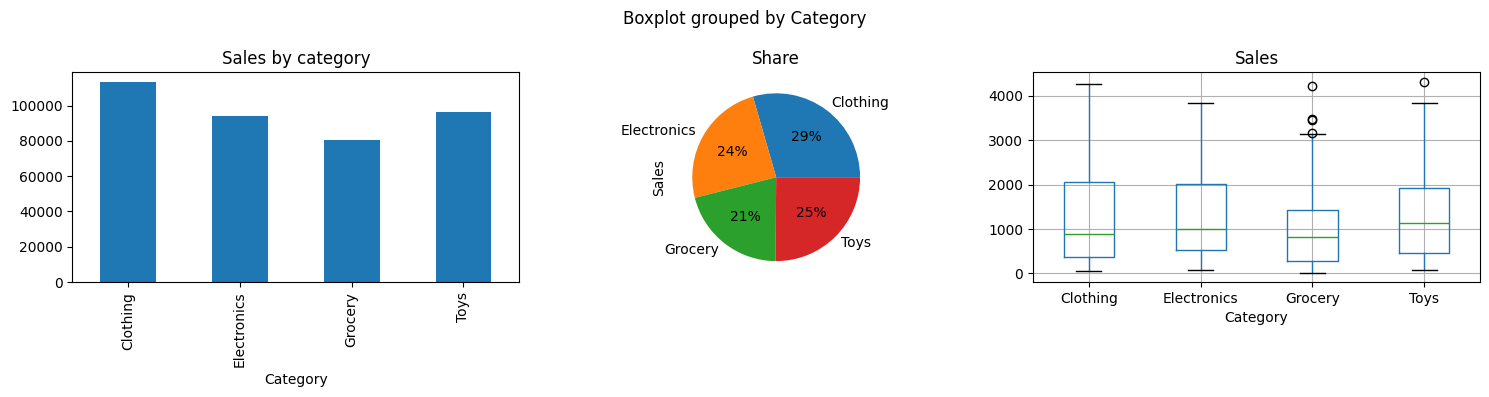

In [3]:
import pandas as pd, matplotlib.pyplot as plt

# 1. Load
csv, xls, js = pd.read_csv("data/sales.csv"), pd.read_excel("data/sales.xlsx"), pd.read_json("data/sales.json")
# 2. Explore
for n, d in [("CSV", csv), ("Excel", xls), ("JSON", js)]:
    print(n, d.shape, "missing:", d.isna().sum().sum(), "duplicates:", d.duplicated().sum())

# 3-4. Unify + clean
df = pd.concat([csv, xls, js], ignore_index=True).drop_duplicates()
df["UnitPrice"] = df["UnitPrice"].fillna(df["UnitPrice"].median())
df["Date"] = pd.to_datetime(df["Date"])

# 5. Transform: derive new columns
df["Sales"] = df.Quantity * df.UnitPrice
df["Month"] = df.Date.dt.to_period("M").astype(str)

# 6. Analyze
print("Total sales:", round(df.Sales.sum(), 2), "| Avg order value:", round(df.Sales.mean(), 2))
print(df.groupby("Category").Sales.sum().round(2))

# 7. Visualize
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.groupby("Category").Sales.sum().plot.bar(ax=ax[0], title="Sales by category")
df.groupby("Category").Sales.sum().plot.pie(ax=ax[1], autopct="%1.0f%%", title="Share")
df.boxplot("Sales", by="Category", ax=ax[2]); plt.tight_layout(); plt.show()